In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("veda_technology_business_analytics.csv")

# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (1000, 16)

Column names:
['Record_ID', 'Date', 'City', 'Customer_Type', 'Service_Type', 'Internship_Domain', 'Training_Program', 'Marketing_Channel', 'Website_Visitor', 'Pages_Viewed', 'Session_Duration_Min', 'Engagement_Level', 'Inquiry_Received', 'Application_Submitted', 'Inquiry_Status', 'Revenue_INR']


,Record_ID,Date,City,Customer_Type,Service_Type,Internship_Domain,Training_Program,Marketing_Channel,Website_Visitor,Pages_Viewed,Session_Duration_Min,Engagement_Level,Inquiry_Received,Application_Submitted,Inquiry_Status,Revenue_INR
0,VT0001,02-11-2025,Pune,Individual,Digital Services,Not Applicable,Not Applicable,Referral,Yes,4,1.5,Low,Yes,Yes,In Progress,0.0
1,VT0002,10-07-2026,Thane,Startup,Customer Support,Not Applicable,Not Applicable,Email Campaign,Yes,3,8.9,Medium,Yes,No,In Progress,0.0
2,VT0003,27-05-2026,Other,Student,Customer Support,Not Applicable,Not Applicable,LinkedIn,No,4,10.7,Medium,Yes,No,New Inquiry,0.0
3,VT0004,10-03-2026,Bengaluru,Startup,IT Services,Not Applicable,Not Applicable,Instagram,Yes,6,5.6,Medium,Yes,Yes,In Progress,0.0
4,VT0005,08-03-2026,Mumbai,Small Business,IT Services,Not Applicable,Not Applicable,Direct Website,Yes,5,1.6,Low,No,No,Visitor Only,0.0


In [2]:

# Check dataset size
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Summary statistics
df.describe(include="all")

Dataset Shape: (1000, 16)

Column Names:
['Record_ID', 'Date', 'City', 'Customer_Type', 'Service_Type', 'Internship_Domain', 'Training_Program', 'Marketing_Channel', 'Website_Visitor', 'Pages_Viewed', 'Session_Duration_Min', 'Engagement_Level', 'Inquiry_Received', 'Application_Submitted', 'Inquiry_Status', 'Revenue_INR']

Data Types:
Record_ID                 object
Date                      object
City                      object
Customer_Type             object
Service_Type              object
Internship_Domain         object
Training_Program          object
Marketing_Channel         object
Website_Visitor           object
Pages_Viewed               int64
Session_Duration_Min     float64
Engagement_Level          object
Inquiry_Received          object
Application_Submitted     object
Inquiry_Status            object
Revenue_INR              float64
dtype: object

Missing Values:
Record_ID                 0
Date                      0
City                      8
Customer_Type        

,Record_ID,Date,City,Customer_Type,Service_Type,Internship_Domain,Training_Program,Marketing_Channel,Website_Visitor,Pages_Viewed,Session_Duration_Min,Engagement_Level,Inquiry_Received,Application_Submitted,Inquiry_Status,Revenue_INR
count,1000,1000,992,1000,1000,1000,1000,994,1000,1000.000000,993.000000,990,1000,1000,1000,1000.000000
unique,1000,341,8,5,5,6,6,6,2,NaN,NaN,3,2,2,6,NaN
top,VT1000,04-11-2025,Pune,Student,Internship,Not Applicable,Not Applicable,Google Search,Yes,NaN,NaN,Medium,Yes,No,In Progress,NaN
freq,1,9,275,362,245,755,784,237,845,NaN,NaN,495,787,695,231,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.153000,6.209164,NaN,NaN,NaN,NaN,341.425190
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.704238,5.260821,NaN,NaN,NaN,NaN,1948.941647
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.500000,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,2.700000,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,4.800000,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,8.000000,NaN,NaN,NaN,NaN,0.000000


In [3]:

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Convert date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Fill missing categorical values
categorical_cols = [
    "City", "Engagement_Level", "Marketing_Channel"
]

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

# Fill missing session duration with median
df["Session_Duration_Min"] = df[
    "Session_Duration_Min"
].fillna(df["Session_Duration_Min"].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

print("Cleaned shape:", df.shape)

Record_ID                 0
Date                      0
City                      8
Customer_Type             0
Service_Type              0
Internship_Domain         0
Training_Program          0
Marketing_Channel         6
Website_Visitor           0
Pages_Viewed              0
Session_Duration_Min      7
Engagement_Level         10
Inquiry_Received          0
Application_Submitted     0
Inquiry_Status            0
Revenue_INR               0
dtype: int64
Duplicate rows: 0
Missing values after cleaning:
Record_ID                  0
Date                     601
City                       0
Customer_Type              0
Service_Type               0
Internship_Domain          0
Training_Program           0
Marketing_Channel          0
Website_Visitor            0
Pages_Viewed               0
Session_Duration_Min       0
Engagement_Level           0
Inquiry_Received           0
Application_Submitted      0
Inquiry_Status             0
Revenue_INR                0
dtype: int64
Cleaned shape

In [4]:

df.to_csv("veda_cleaned_data.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


Visitor records: 845

Visitors by marketing channel:


Marketing_Channel
Google Search     237
LinkedIn          185
Direct Website    177
Instagram         162
Referral          132
Email Campaign    101
Unknown             6
Name: count, dtype: int64


Average session duration: 6.2 minutes

Average pages viewed: 4.15


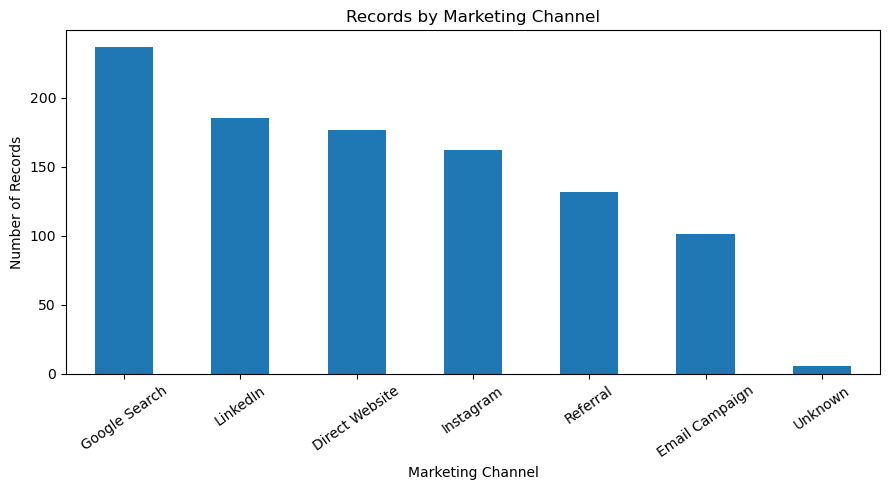

In [5]:

# Website visitor analysis
print("Visitor records:",
      (df["Website_Visitor"] == "Yes").sum())

print("\nVisitors by marketing channel:")
display(df["Marketing_Channel"].value_counts())

print("\nAverage session duration:",
      round(df["Session_Duration_Min"].mean(), 2), "minutes")

print("\nAverage pages viewed:",
      round(df["Pages_Viewed"].mean(), 2))

# Visualize marketing channels
df["Marketing_Channel"].value_counts().plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Records by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

Internship records: 245

Applications submitted:
Application_Submitted
Yes    140
No     105
Name: count, dtype: int64

Internship domain analysis:


,Internship_Domain,count
0,Cyber Security,57
1,Data Science,50
2,Python Development,48
3,Data Analytics,45
4,Web Development,45


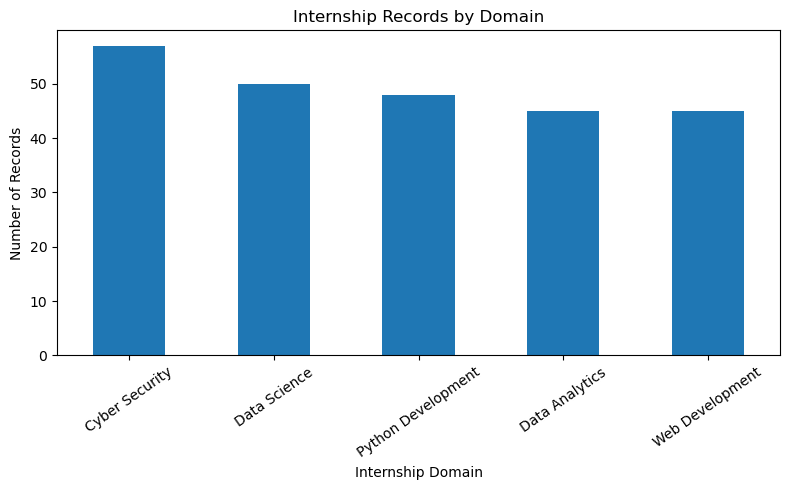

In [6]:

internships = df[df["Service_Type"] == "Internship"]

print("Internship records:", len(internships))

print("\nApplications submitted:")
print(internships["Application_Submitted"].value_counts())

print("\nInternship domain analysis:")
display(
    internships["Internship_Domain"]
    .value_counts()
    .reset_index()
)

internships["Internship_Domain"].value_counts().plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Internship Records by Domain")
plt.xlabel("Internship Domain")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

Training records: 216

Training program distribution:


Training_Program
Machine Learning           51
Power BI Analytics         45
SQL Fundamentals           44
Python for Data Science    44
Excel for Business         32
Name: count, dtype: int64


Applications by training program:


,Training_Program,Applications
0,Excel for Business,16
1,Machine Learning,30
2,Power BI Analytics,21
3,Python for Data Science,16
4,SQL Fundamentals,18


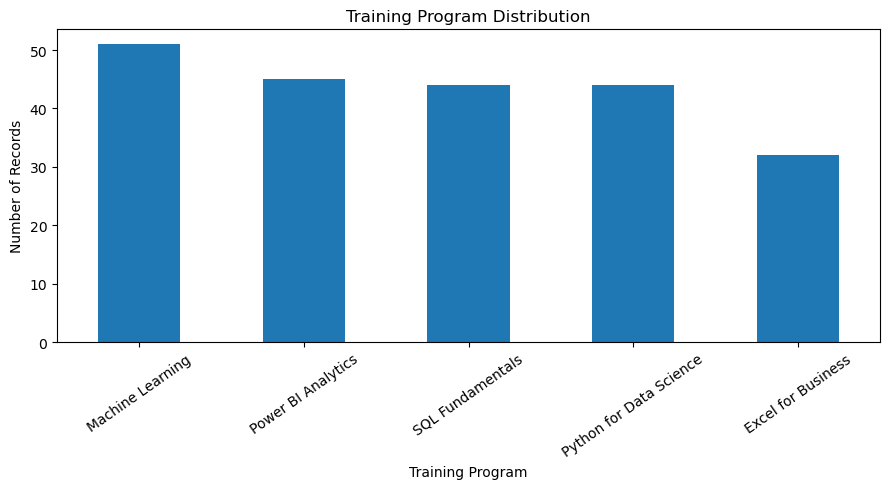

In [7]:
#Training program performance

training = df[df["Service_Type"] == "Training Program"]

print("Training records:", len(training))

print("\nTraining program distribution:")
display(training["Training_Program"].value_counts())

print("\nApplications by training program:")
display(
    training.groupby("Training_Program")
    ["Application_Submitted"]
    .apply(lambda s: (s == "Yes").sum())
    .reset_index(name="Applications")
)

training["Training_Program"].value_counts().plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Training Program Distribution")
plt.xlabel("Training Program")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [8]:
#IT and digital service inquiry analysis

service_data = df[
    df["Service_Type"].isin(
        ["IT Services", "Digital Services"]
    )
]

print("IT and digital service records:", len(service_data))

print("\nRecords by service:")
display(service_data["Service_Type"].value_counts())

print("\nInquiry status by service:")
display(pd.crosstab(
    service_data["Service_Type"],
    service_data["Inquiry_Status"]
))

print("\nRevenue by service:")
display(
    service_data.groupby("Service_Type")["Revenue_INR"]
    .sum()
    .reset_index()
)

IT and digital service records: 370

Records by service:


Service_Type
IT Services         202
Digital Services    168
Name: count, dtype: int64


Inquiry status by service:


Inquiry_Status,Applied,Closed,Converted,In Progress,New Inquiry,Visitor Only
Service_Type,,,,,,
Digital Services,6,26,5,33,49,49
IT Services,9,27,7,45,64,50



Revenue by service:


,Service_Type,Revenue_INR
0,Digital Services,62001.25
1,IT Services,130719.63


Customer type distribution:


Customer_Type
Student           362
Individual        209
Small Business    197
Startup           135
Enterprise         97
Name: count, dtype: int64


Inquiry records by customer type:


,Customer_Type,Total_Inquiries
0,Enterprise,75
1,Individual,170
2,Small Business,155
3,Startup,107
4,Student,280



Inquiry status distribution:


Inquiry_Status
In Progress     231
New Inquiry     228
Visitor Only    213
Applied         129
Closed          115
Converted        84
Name: count, dtype: int64

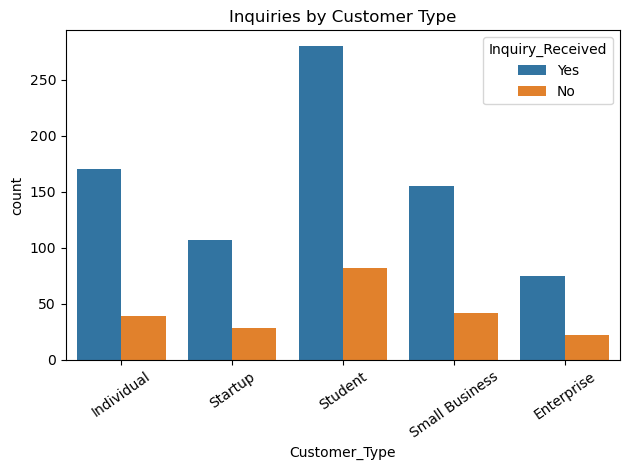

In [9]:
#Customer and service request analysis

print("Customer type distribution:")
display(df["Customer_Type"].value_counts())

print("\nInquiry records by customer type:")
display(
    df.groupby("Customer_Type")["Inquiry_Received"]
    .apply(lambda s: (s == "Yes").sum())
    .reset_index(name="Total_Inquiries")
)

print("\nInquiry status distribution:")
display(df["Inquiry_Status"].value_counts())

sns.countplot(
    data=df, x="Customer_Type", hue="Inquiry_Received"
)
plt.title("Inquiries by Customer Type")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [10]:
#Marketing channel performance

marketing = df.groupby("Marketing_Channel").agg(
    Total_Records=("Record_ID", "count"),
    Total_Inquiries=(
        "Inquiry_Received",
        lambda s: (s == "Yes").sum()
    ),
    Total_Applications=(
        "Application_Submitted",
        lambda s: (s == "Yes").sum()
    ),
    Total_Revenue=("Revenue_INR", "sum")
).reset_index()

marketing["Inquiry_Rate_Percent"] = (
    marketing["Total_Inquiries"]
    / marketing["Total_Records"] * 100
).round(2)

marketing["Application_Rate_Percent"] = (
    marketing["Total_Applications"]
    / marketing["Total_Records"] * 100
).round(2)

display(marketing.sort_values(
    "Total_Inquiries", ascending=False
))

,Marketing_Channel,Total_Records,Total_Inquiries,Total_Applications,Total_Revenue,Inquiry_Rate_Percent,Application_Rate_Percent
2,Google Search,237,177,69,60298.73,74.68,29.11
4,LinkedIn,185,146,54,91838.26,78.92,29.19
0,Direct Website,177,141,58,42021.64,79.66,32.77
3,Instagram,162,130,51,98354.46,80.25,31.48
5,Referral,132,103,43,8356.00,78.03,32.58
1,Email Campaign,101,85,29,22161.40,84.16,28.71
6,Unknown,6,5,1,18394.70,83.33,16.67


,Customer_Type,Engagement_Level,Total_Records,Total_Inquiries,Total_Revenue
0,Enterprise,High,22,18,23745.94
1,Enterprise,Low,20,18,0.00
2,Enterprise,Medium,55,39,7532.66
3,Individual,High,44,37,0.00
4,Individual,Low,56,43,18841.49
5,Individual,Medium,106,87,43388.65
6,Individual,Unknown,3,3,0.00
7,Small Business,High,46,34,4800.00
8,Small Business,Low,57,47,18394.70
9,Small Business,Medium,94,74,53726.64


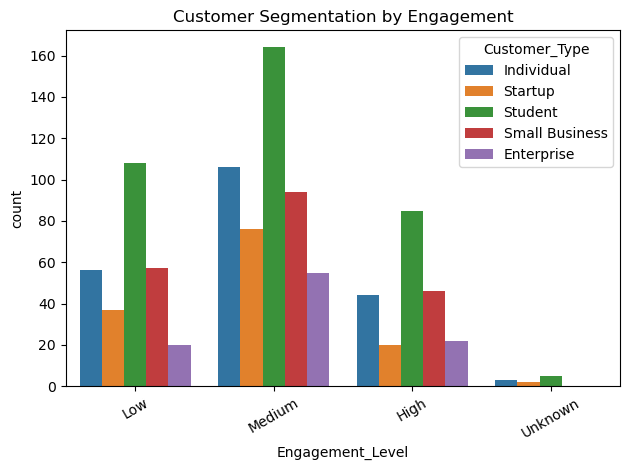

In [11]:
#Customer segmentation

segment_analysis = df.groupby(
    ["Customer_Type", "Engagement_Level"],
    dropna=False
).agg(
    Total_Records=("Record_ID", "count"),
    Total_Inquiries=(
        "Inquiry_Received",
        lambda s: (s == "Yes").sum()
    ),
    Total_Revenue=("Revenue_INR", "sum")
).reset_index()

display(segment_analysis)

sns.countplot(
    data=df, x="Engagement_Level",
    hue="Customer_Type"
)
plt.title("Customer Segmentation by Engagement")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Service_Type,Total_Records,Total_Inquiries,Total_Applications,Total_Revenue
3,Internship,245,192,140,0.00
4,Training Program,216,167,101,134272.71
0,Customer Support,169,157,21,14431.60
2,IT Services,202,152,23,130719.63
1,Digital Services,168,119,20,62001.25


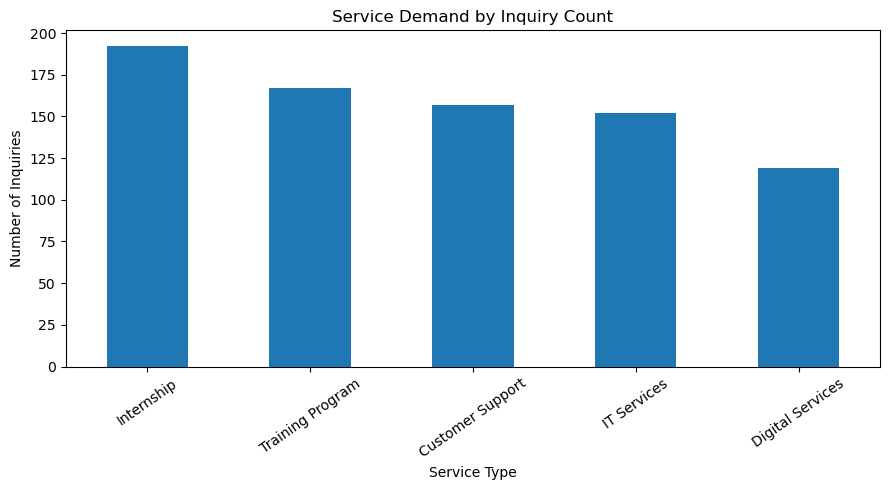

In [12]:
#Service demand analysis

service_demand = df.groupby("Service_Type").agg(
    Total_Records=("Record_ID", "count"),
    Total_Inquiries=(
        "Inquiry_Received",
        lambda s: (s == "Yes").sum()
    ),
    Total_Applications=(
        "Application_Submitted",
        lambda s: (s == "Yes").sum()
    ),
    Total_Revenue=("Revenue_INR", "sum")
).reset_index()

service_demand = service_demand.sort_values(
    "Total_Inquiries", ascending=False
)

display(service_demand)

service_demand.plot(
    x="Service_Type",
    y="Total_Inquiries",
    kind="bar",
    legend=False,
    figsize=(9, 5)
)
plt.title("Service Demand by Inquiry Count")
plt.xlabel("Service Type")
plt.ylabel("Number of Inquiries")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [13]:
#Business KPIs

total_records = len(df)
total_visitors = (df["Website_Visitor"] == "Yes").sum()
total_inquiries = (df["Inquiry_Received"] == "Yes").sum()
total_applications = (
    df["Application_Submitted"] == "Yes"
).sum()
total_revenue = df["Revenue_INR"].sum()

inquiry_rate = (
    total_inquiries / total_records * 100
    if total_records else 0
)

application_rate = (
    total_applications / total_records * 100
    if total_records else 0
)

print("Total Records:", total_records)
print("Website Visitor Records:", total_visitors)
print("Total Inquiries:", total_inquiries)
print("Total Applications:", total_applications)
print("Total Simulated Revenue: ₹", round(total_revenue, 2))
print("Inquiry Rate (%):", round(inquiry_rate, 2))
print("Application Rate (%):", round(application_rate, 2))

Total Records: 1000
Website Visitor Records: 845
Total Inquiries: 787
Total Applications: 305
Total Simulated Revenue: ₹ 341425.19
Inquiry Rate (%): 78.7
Application Rate (%): 30.5


In [14]:
#Predictive analysis using Machine Learning

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)

# Avoid using the outcome or fields that reveal the outcome.
features = [
    "City",
    "Customer_Type",
    "Service_Type",
    "Internship_Domain",
    "Training_Program",
    "Marketing_Channel",
    "Website_Visitor",
    "Pages_Viewed",
    "Session_Duration_Min",
    "Engagement_Level",
    "Inquiry_Received"
]

X = df[features].copy()
y = (df["Application_Submitted"] == "Yes").astype(int)

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),

    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, predictions), 3
))
print("\nClassification Report:")
print(classification_report(
    y_test, predictions, zero_division=0
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

Accuracy: 0.825

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88       139
           1       0.75      0.64      0.69        61

    accuracy                           0.82       200
   macro avg       0.80      0.77      0.78       200
weighted avg       0.82      0.82      0.82       200

Confusion Matrix:
[[126  13]
 [ 22  39]]


,Month,Total_Records,Total_Inquiries,Total_Applications,Total_Revenue
0,2025-01,6,6,2,3131.71
1,2025-02,11,9,5,13035.56
2,2025-03,13,10,3,0.00
3,2025-04,13,10,2,0.00
4,2025-05,7,5,4,0.00
5,2025-06,10,9,2,0.00
6,2025-07,4,3,2,0.00
7,2025-08,9,9,2,0.00
8,2025-09,8,5,2,0.00
9,2025-10,5,3,2,0.00


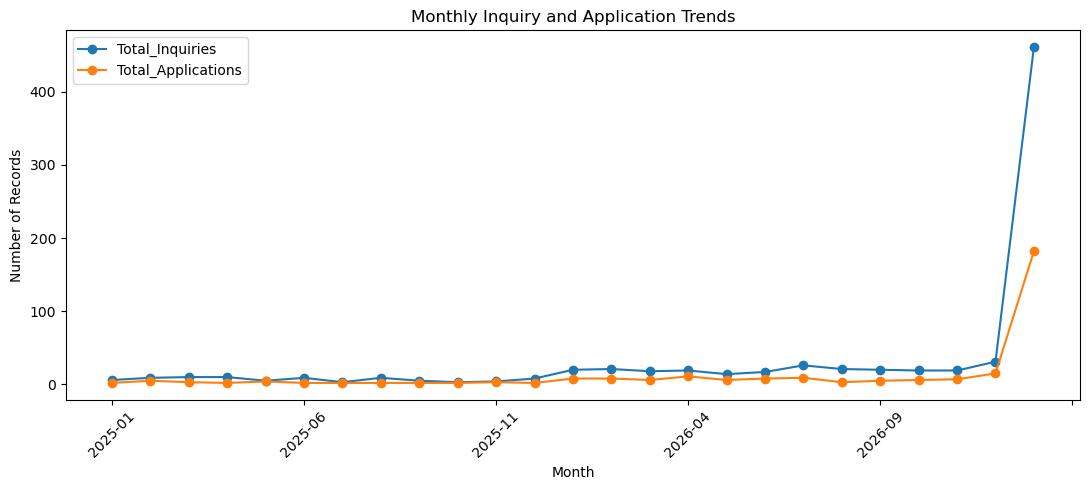

In [15]:
#Monthly business trend analysis

df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly = df.groupby("Month").agg(
    Total_Records=("Record_ID", "count"),
    Total_Inquiries=(
        "Inquiry_Received",
        lambda s: (s == "Yes").sum()
    ),
    Total_Applications=(
        "Application_Submitted",
        lambda s: (s == "Yes").sum()
    ),
    Total_Revenue=("Revenue_INR", "sum")
).reset_index()

display(monthly)

monthly.plot(
    x="Month",
    y=["Total_Inquiries", "Total_Applications"],
    marker="o",
    figsize=(11, 5)
)
plt.title("Monthly Inquiry and Application Trends")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
#Export the final analysis files

# Save cleaned dataset
df.to_csv("veda_cleaned_data.csv", index=False)

# Save analysis tables
with pd.ExcelWriter(
    "veda_business_analysis_report.xlsx",
    engine="openpyxl"
) as writer:
    service_demand.to_excel(
        writer, sheet_name="Service_Demand", index=False
    )
    marketing.to_excel(
        writer, sheet_name="Marketing_Analysis", index=False
    )
    segment_analysis.to_excel(
        writer, sheet_name="Customer_Segments", index=False
    )
    monthly.to_excel(
        writer, sheet_name="Monthly_Trends", index=False
    )

print("Analysis files saved successfully.")


Analysis files saved successfully.
